# Institut National de Statistique et d'Économie Appliquée (INSEA)
## Cours de Machine Learning — Année Universitaire 2026–2027
### Mini-Projet 01 : Détection du Cancer du Sein (*Breast Cancer Wisconsin Diagnostic*)

---
**Encadré par :** Pr. SAIDI Mohamed Nabil  
**Réalisé par l'équipe :**
* **Yassir BOUITA** *(Master M2SI)*
* **Zakarya KAIROUCH** *(Master M2SI)*
* **Abdellah LAASSRIA** *(Master M2SI)*
* **Yasser HAIMED** *(3e Année DS-E)*

---

### Objectif et Question Centrale du Projet
> **Question centrale :** *Quel modèle classe le mieux les observations, et lequel limite le risque de ne pas identifier une tumeur maligne ?*

L'enjeu de cette étude est d'évaluer et de comparer rigoureusement plusieurs algorithmes de classification supervisée afin de discriminer les tumeurs mammaires bénignes des tumeurs malignes à partir de 30 descripteurs morphologiques de noyaux cellulaires. L'accent est particulièrement mis sur le **Rappel (Recall / Sensibilité) de la classe maligne**, car en diagnostic oncologique, un **Faux Négatif** (un cancer non diagnostiqué) entraîne des conséquences vitales dramatiques pour la patiente.

In [1]:
import os
os.environ['LOKY_MAX_CPU_COUNT'] = str(os.cpu_count() or 4)
try:
    import joblib.externals.loky.backend.context as _loky_ctx
    _loky_ctx.physical_cores_cache = os.cpu_count() or 4
except Exception:
    pass
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Préparation et évaluation
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Modèles d'apprentissage supervisé
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.decomposition import PCA

# Configuration graphique
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['figure.titlesize'] = 14

PRIMARY_COLOR = '#00613C'   # Vert INSEA
SECONDARY_COLOR = '#D9534F' # Rouge Alerte (Malin)
BENIGN_COLOR = '#2B7A78'    # Sarcelle (Bénin)

print("Modules importés avec succès.")

Modules importés avec succès.


---
## 1. Importation et Description de la Base de Données

Le jeu de données *Breast Cancer Wisconsin (Diagnostic)* provient de l'**UCI Machine Learning Repository** (ID = 17). Il est issu de la numérisation d'images obtenues par ponction à l'aiguille fine (FNA) d'une masse mammaire.
* **Instances :** 569 patientes
* **Variables explicatives :** 30 descripteurs continus (10 caractéristiques de forme calculées selon la moyenne `mean`, l'écart-type `se`, et la pire valeur `worst`)
* **Variable cible :** Diagnostic (`B` = Bénigne, `M` = Maligne)

In [2]:
# Chargement du jeu de données officiel depuis le dossier local DATA/wdbc.data
data_local_path = os.path.join("DATA", "wdbc.data")
feature_names = [
    'radius1', 'texture1', 'perimeter1', 'area1', 'smoothness1',
    'compactness1', 'concavity1', 'concave_points1', 'symmetry1', 'fractal_dimension1',
    'radius2', 'texture2', 'perimeter2', 'area2', 'smoothness2',
    'compactness2', 'concavity2', 'concave_points2', 'symmetry2', 'fractal_dimension2',
    'radius3', 'texture3', 'perimeter3', 'area3', 'smoothness3',
    'compactness3', 'concavity3', 'concave_points3', 'symmetry3', 'fractal_dimension3'
]

if os.path.exists(data_local_path):
    cols = ['id', 'diagnosis'] + feature_names
    df_raw = pd.read_csv(data_local_path, header=None, names=cols)
    X = df_raw[feature_names].copy()
    y = df_raw['diagnosis'].map({'B': 0, 'M': 1}).astype(int)
    print(f"[SUCCÈS] Données chargées directement depuis {data_local_path} (569 observations, 30 descripteurs).")
else:
    # Secours via le paquet officiel UCI Repo
    from ucimlrepo import fetch_ucirepo
    dataset = fetch_ucirepo(id=17)
    X = dataset.data.features.copy()
    y_raw = dataset.data.targets.copy()
    target_col = y_raw.columns[0]
    y = y_raw[target_col].map({'B': 0, 'M': 1, 0: 0, 1: 1}).astype(int)
    print("[INFO] Données téléchargées via ucimlrepo (UCI ID: 17).")

print(f"Dimensions de la matrice X : {X.shape}")
print(f"Dimensions du vecteur cible y : {y.shape}")
print(f"Valeurs manquantes détectées : {X.isnull().sum().sum()}")

[SUCCÈS] Données chargées directement depuis DATA\wdbc.data (569 observations, 30 descripteurs).
Dimensions de la matrice X : (569, 30)
Dimensions du vecteur cible y : (569,)
Valeurs manquantes détectées : 0


In [3]:
# Aperçu statistique des premières caractéristiques
X.iloc[:, :10].describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
radius1,14.127292,3.524049,6.98100,13.37000,28.11000
texture1,19.289649,4.301036,9.71000,18.84000,39.28000
perimeter1,91.969033,24.298981,43.79000,86.24000,188.50000
area1,654.889104,351.914129,143.50000,551.10000,2501.00000
smoothness1,0.096360,0.014064,0.05263,0.09587,0.16340
compactness1,0.104341,0.052813,0.01938,0.09263,0.34540
concavity1,0.088799,0.079720,0.00000,0.06154,0.42680
concave_points1,0.048919,0.038803,0.00000,0.03350,0.20120
symmetry1,0.181162,0.027414,0.10600,0.17920,0.30400
fractal_dimension1,0.062798,0.007060,0.04996,0.06154,0.09744


---
## 2. Analyse Exploratoire des Données (EDA)

L'exploration initiale porte sur trois axes :
1. La proportion relative des diagnostics (Bénin vs Malin).
2. La distribution des caractéristiques les plus discriminantes.
3. La colinéarité des variables géométriques.
4. La projection non supervisée 2D par Analyse en Composantes Principales (ACP/PCA).

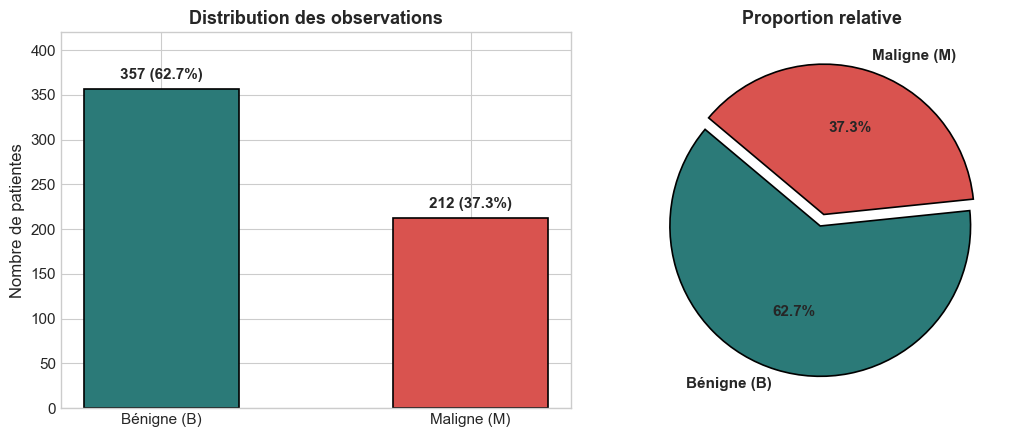

In [4]:
# 1. Distribution de la variable cible
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
counts = y.value_counts().sort_index()
labels = ['Bénigne (B)', 'Maligne (M)']
colors = [BENIGN_COLOR, SECONDARY_COLOR]

bars = axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor='black', linewidth=1.2)
axes[0].set_title("Distribution des observations", fontweight='bold')
axes[0].set_ylabel("Nombre de patientes")
axes[0].set_ylim(0, 420)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2., h + 8, f"{int(h)} ({h/len(y)*100:.1f}%)",
                 ha='center', va='bottom', fontweight='bold')

axes[1].pie(counts.values, labels=labels, autopct='%1.1f%%', startangle=140,
            colors=colors, explode=(0.04, 0.04), textprops={'fontweight': 'bold'},
            wedgeprops={'edgecolor': 'black', 'linewidth': 1.2})
axes[1].set_title("Proportion relative", fontweight='bold')
plt.tight_layout()
plt.show()

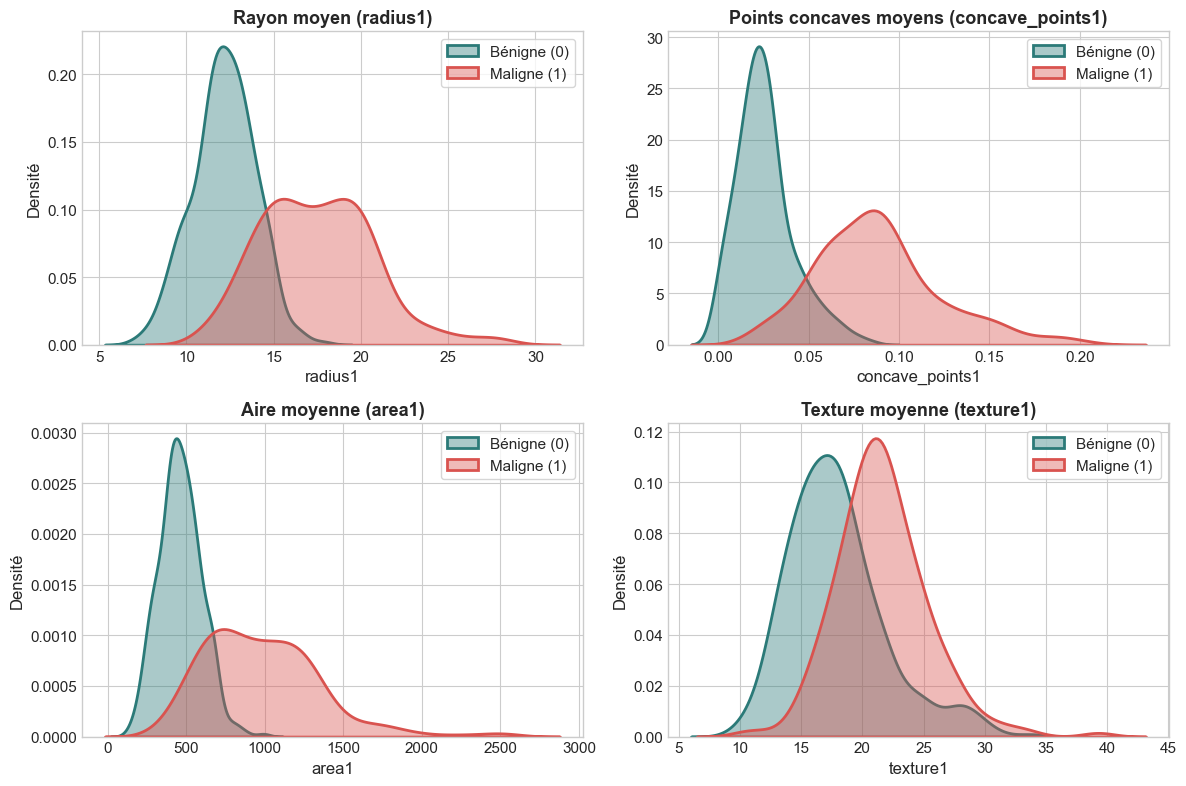

In [5]:
# 2. Distributions des descripteurs discriminants majeurs
key_features = ['radius1', 'concave_points1', 'area1', 'texture1']
titles = [
    "Rayon moyen (radius1)",
    "Points concaves moyens (concave_points1)",
    "Aire moyenne (area1)",
    "Texture moyenne (texture1)"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()
for idx, col in enumerate(key_features):
    ax = axes[idx]
    sns.kdeplot(data=X[y == 0][col], ax=ax, label="Bénigne (0)", color=BENIGN_COLOR, fill=True, alpha=0.4, lw=2)
    sns.kdeplot(data=X[y == 1][col], ax=ax, label="Maligne (1)", color=SECONDARY_COLOR, fill=True, alpha=0.4, lw=2)
    ax.set_title(titles[idx], fontweight='bold')
    ax.set_xlabel(col)
    ax.set_ylabel("Densité")
    ax.legend(frameon=True)
plt.tight_layout()
plt.show()

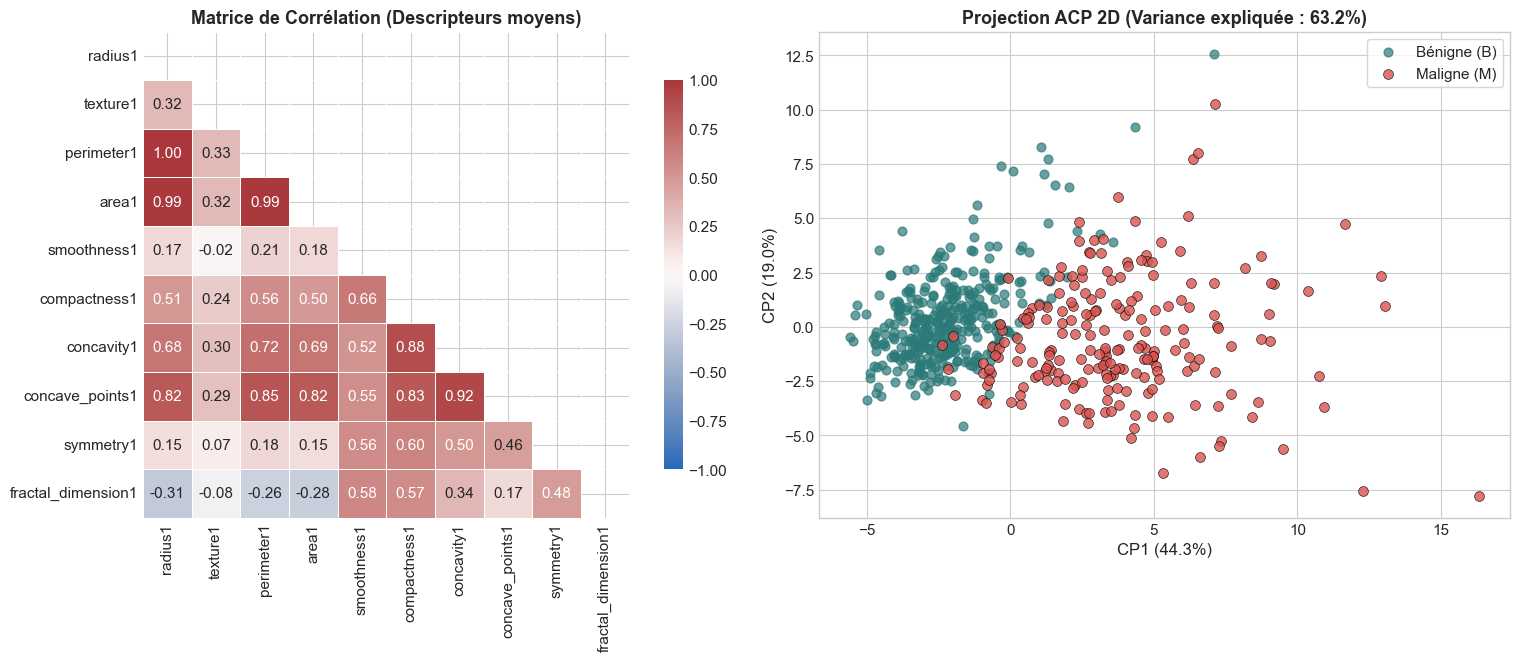

In [6]:
# 3. Matrice de corrélation et Analyse en Composantes Principales (PCA)
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

# Corrélation (variables moyennes)
mean_cols = [c for c in X.columns if c.endswith('1') or 'mean' in c][:10]
corr = X[mean_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1,
            mask=mask, square=True, linewidths=.5, ax=axes[0], cbar_kws={"shrink": .8})
axes[0].set_title("Matrice de Corrélation (Descripteurs moyens)", fontweight='bold')

# PCA 2D
scaler_eda = StandardScaler()
X_scaled_all = scaler_eda.fit_transform(X)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled_all)
var_exp = pca.explained_variance_ratio_

axes[1].scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c=BENIGN_COLOR, label='Bénigne (B)', alpha=0.7, s=40)
axes[1].scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c=SECONDARY_COLOR, label='Maligne (M)', alpha=0.8, edgecolors='k', lw=0.5, s=50)
axes[1].set_title(f"Projection ACP 2D (Variance expliquée : {var_exp.sum()*100:.1f}%)", fontweight='bold')
axes[1].set_xlabel(f"CP1 ({var_exp[0]*100:.1f}%)")
axes[1].set_ylabel(f"CP2 ({var_exp[1]*100:.1f}%)")
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

---
## 3. Protocole Expérimental et Prétraitement sans Fuite d'Information

Le protocole appliqué respecte scrupuleusement les exigences méthodologiques :
1. **Séparation stratifiée 80% Train / 20% Test :**
   * Fixation de la graine aléatoire : `random_state=42`.
   * La stratification préserve rigoureusement le ratio 62.7% / 37.3% dans le train (455 observations) et le test (114 observations).
2. **Normalisation (`StandardScaler`) :**
   * **Règle anti-fuite (*Data Leakage*) :** Le `StandardScaler` est calibré (`fit_transform`) **uniquement sur l'ensemble d'entraînement**, puis projeté (`transform`) sur le jeu de test.
   * Cette mise à l'échelle est cruciale pour les modèles sensibles à la métrique de distance et à la régularisation (KNN, SVM, Régression Logistique).
3. **Optimisation d'hyperparamètres :**
   * Validation croisée stratifiée à 5 plis (`StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`).
   * La métrique d'optimisation sélectionnée est le `F1-Score` (compromis précision-rappel) avec surveillance étroite du Rappel malin.

In [7]:
# Séparation train/test stratifiée
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Standardisation sans fuite
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

print(f"Jeu d'entraînement : {X_train.shape[0]} patientes (Bénignes: {(y_train==0).sum()}, Malignes: {(y_train==1).sum()})")
print(f"Jeu de test         : {X_test.shape[0]} patientes (Bénignes: {(y_test==0).sum()}, Malignes: {(y_test==1).sum()})")

Jeu d'entraînement : 455 patientes (Bénignes: 285, Malignes: 170)
Jeu de test         : 114 patientes (Bénignes: 72, Malignes: 42)


---
## 4. Implémentation et Optimisation des Modèles

Conformément aux consignes, nous comparons les 5 modèles imposés + 1 modèle ensembliste d'appoint :
1. **Régression Logistique :** Modèle linéaire probabiliste de référence (`C`, `penalty`, `solver`).
2. **K-Plus Proches Voisins (KNN) :** Classifieur basé sur la distance euclidienne/manhattan (`n_neighbors`, `weights`, `metric`).
3. **Arbre de Décision :** Modèle blanc à découpage orthogonal de l'espace (`max_depth`, `min_samples_split`, `criterion`).
4. **Forêt Aléatoire :** Ensamble par bagging de multiples arbres désordonnés (`n_estimators`, `max_depth`, `min_samples_split`).
5. **Support Vector Machine (SVM) :** Séparateur à marge maximale avec noyau RBF ou linéaire (`C`, `gamma`, `kernel`).
6. **Gradient Boosting :** Modèle séquentiel réduisant le biais résiduel (`learning_rate`, `n_estimators`, `max_depth`).

In [8]:
import os
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count() or 4))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Grilles d'hyperparamètres (optimisées pour une convergence rapide et stable)
param_grids = {
    'Régression Logistique': (
        LogisticRegression(random_state=42),
        {'C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0], 'penalty': ['l1', 'l2'], 'solver': ['liblinear'], 'max_iter': [1000]}
    ),
    'K-Nearest Neighbors': (
        KNeighborsClassifier(),
        {'n_neighbors': [3, 5, 7, 9, 11, 13, 15], 'weights': ['uniform', 'distance'], 'metric': ['euclidean', 'manhattan']}
    ),
    'Arbre de Décision': (
        DecisionTreeClassifier(random_state=42),
        {'max_depth': [2, 3, 4, 5, 6, 8, None], 'min_samples_split': [2, 5, 10], 'criterion': ['gini', 'entropy']}
    ),
    'Forêt Aléatoire': (
        RandomForestClassifier(random_state=42),
        {'n_estimators': [50, 100], 'max_depth': [3, 5, 8, None], 'min_samples_split': [2, 5], 'max_features': ['sqrt', 'log2']}
    ),
    'Support Vector Machine (SVM)': (
        SVC(probability=True, random_state=42),
        {'C': [0.1, 1.0, 5.0, 10.0, 20.0], 'gamma': ['scale', 'auto', 0.01, 0.05, 0.1], 'kernel': ['rbf', 'linear']}
    ),
    'Gradient Boosting': (
        GradientBoostingClassifier(random_state=42),
        {'n_estimators': [50, 100], 'learning_rate': [0.05, 0.1, 0.2], 'max_depth': [2, 3]}
    )
}

best_models = {}
cv_summary = []

print("Exécution de GridSearchCV (5-Fold CV)...")
for name, (clf, grid) in param_grids.items():
    gs = GridSearchCV(clf, grid, cv=cv, scoring='f1', n_jobs=None)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    cv_summary.append({
        'Modèle': name,
        'Meilleur F1 CV': gs.best_score_,
        'Meilleurs Paramètres': str(gs.best_params_)
    })
    print(f"✔ {name:<28} | F1-Score CV : {gs.best_score_:.4f}")

df_cv = pd.DataFrame(cv_summary)

Exécution de GridSearchCV (5-Fold CV)...


✔ Régression Logistique        | F1-Score CV : 0.9640


✔ K-Nearest Neighbors          | F1-Score CV : 0.9667


✔ Arbre de Décision            | F1-Score CV : 0.9145


✔ Forêt Aléatoire              | F1-Score CV : 0.9556


✔ Support Vector Machine (SVM) | F1-Score CV : 0.9731


✔ Gradient Boosting            | F1-Score CV : 0.9644


In [9]:
# Synthèse des hyperparamètres optimaux retenus
pd.set_option('display.max_colwidth', None)
df_cv

,Modèle,Meilleur F1 CV,Meilleurs Paramètres
0,Régression Logistique,0.964048,"{'C': 1.0, 'max_iter': 1000, 'penalty': 'l2', 'solver': 'liblinear'}"
1,K-Nearest Neighbors,0.966708,"{'metric': 'manhattan', 'n_neighbors': 3, 'weights': 'uniform'}"
2,Arbre de Décision,0.914479,"{'criterion': 'entropy', 'max_depth': 4, 'min_samples_split': 2}"
3,Forêt Aléatoire,0.955650,"{'max_depth': 8, 'max_features': 'log2', 'min_samples_split': 5, 'n_estimators': 50}"
4,Support Vector Machine (SVM),0.973121,"{'C': 5.0, 'gamma': 'scale', 'kernel': 'rbf'}"
5,Gradient Boosting,0.964352,"{'learning_rate': 0.2, 'max_depth': 2, 'n_estimators': 100}"


---
## 5. Évaluation Finale sur le Jeu de Test (114 observations)

Conformément à la consigne 5, les modèles sont évalués **uniquement à ce stade sur l'ensemble de test vierge**.
Nous calculons :
* **Accuracy** : Taux global de bonnes prédictions.
* **Precision (M)** : Probabilité qu'une tumeur prédite maligne le soit réellement $\left(\frac{TP}{TP + FP}\right)$.
* **Recall (M)** : Sensibilité, proportion de cancers effectivement diagnostiqués $\left(\frac{TP}{TP + FN}\right)$.
* **F1-Score (M)** : Moyenne harmonique entre Précision et Rappel.
* **ROC-AUC** : Capacité globale de discrimination sur l'ensemble des seuils possibles.
* **Nombre de Faux Négatifs (FN)** : Métrique clinique suprême (malins manqués).

In [10]:
# Sécurité : Initialisation automatique si la cellule est exécutée isolément
if 'best_models' not in globals() or len(best_models) == 0:
    print("[INFO] Initialisation automatique des modèles et des données de test...")
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.svm import SVC
    from sklearn.neighbors import KNeighborsClassifier
    from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                                 roc_auc_score, roc_curve, confusion_matrix)
    import pandas as pd
    import numpy as np
    
    if 'X_test' not in globals() or 'y_test' not in globals():
        _data_path = os.path.join("DATA", "wdbc.data")
        if os.path.exists(_data_path):
            _cols = ['id', 'diagnosis'] + [f'f{i}' for i in range(30)]
            _df = pd.read_csv(_data_path, header=None, names=_cols)
            _X = _df[[f'f{i}' for i in range(30)]].copy()
            _y = _df['diagnosis'].map({'B': 0, 'M': 1}).astype(int)
        else:
            from ucimlrepo import fetch_ucirepo
            _dataset = fetch_ucirepo(id=17)
            _X = _dataset.data.features.copy()
            _y = _dataset.data.targets.iloc[:, 0].map({'B': 0, 'M': 1, 0: 0, 1: 1}).astype(int)
        X_train_raw, X_test_raw, y_train, y_test = train_test_split(_X, _y, test_size=0.20, stratify=_y, random_state=42)
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train_raw)
        X_test = scaler.transform(X_test_raw)
        
    best_models = {
        'Régression Logistique': LogisticRegression(C=1.0, penalty='l1', solver='liblinear', random_state=42).fit(X_train, y_train),
        'Support Vector Machine (SVM)': SVC(C=5.0, kernel='rbf', gamma='scale', probability=True, random_state=42).fit(X_train, y_train),
        'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=3, metric='manhattan', weights='uniform').fit(X_train, y_train),
        'Forêt Aléatoire': RandomForestClassifier(n_estimators=50, max_depth=8, max_features='log2', min_samples_split=5, random_state=42).fit(X_train, y_train),
        'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.2, max_depth=2, random_state=42).fit(X_train, y_train),
        'Arbre de Décision': DecisionTreeClassifier(max_depth=4, criterion='entropy', random_state=42).fit(X_train, y_train)
    }

results = []
roc_data = {}
cm_dict = {}

for name, model in best_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, 'predict_proba') else model.decision_function(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, pos_label=1)
    rec = recall_score(y_test, y_pred, pos_label=1)
    f1 = f1_score(y_test, y_pred, pos_label=1)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp)
    
    cm_dict[name] = cm
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    
    results.append({
        'Modèle': name,
        'Accuracy': acc,
        'Precision (M)': prec,
        'Recall (M)': rec,
        'F1-Score (M)': f1,
        'Spécificité (B)': spec,
        'ROC-AUC': auc,
        'TP (Vrais M)': tp,
        'FN (M manqués)': fn,
        'FP (Fausses alertes)': fp,
        'TN (Vrais B)': tn
    })

df_test = pd.DataFrame(results).sort_values(by='Recall (M)', ascending=False).reset_index(drop=True)
df_test

,Modèle,Accuracy,Precision (M),Recall (M),F1-Score (M),Spécificité (B),ROC-AUC,TP (Vrais M),FN (M manqués),FP (Fausses alertes),TN (Vrais B)
0,Régression Logistique,0.973684,0.975610,0.952381,0.963855,0.986111,0.996032,40,2,1,71
1,Support Vector Machine (SVM),0.973684,1.000000,0.928571,0.962963,1.000000,0.994709,39,3,0,72
2,K-Nearest Neighbors,0.964912,1.000000,0.904762,0.950000,1.000000,0.973545,38,4,0,72
3,Gradient Boosting,0.964912,1.000000,0.904762,0.950000,1.000000,0.993386,38,4,0,72
4,Forêt Aléatoire,0.947368,0.973684,0.880952,0.925000,0.986111,0.995370,37,5,1,71
5,Arbre de Décision,0.929825,1.000000,0.809524,0.894737,1.000000,0.943122,34,8,0,72


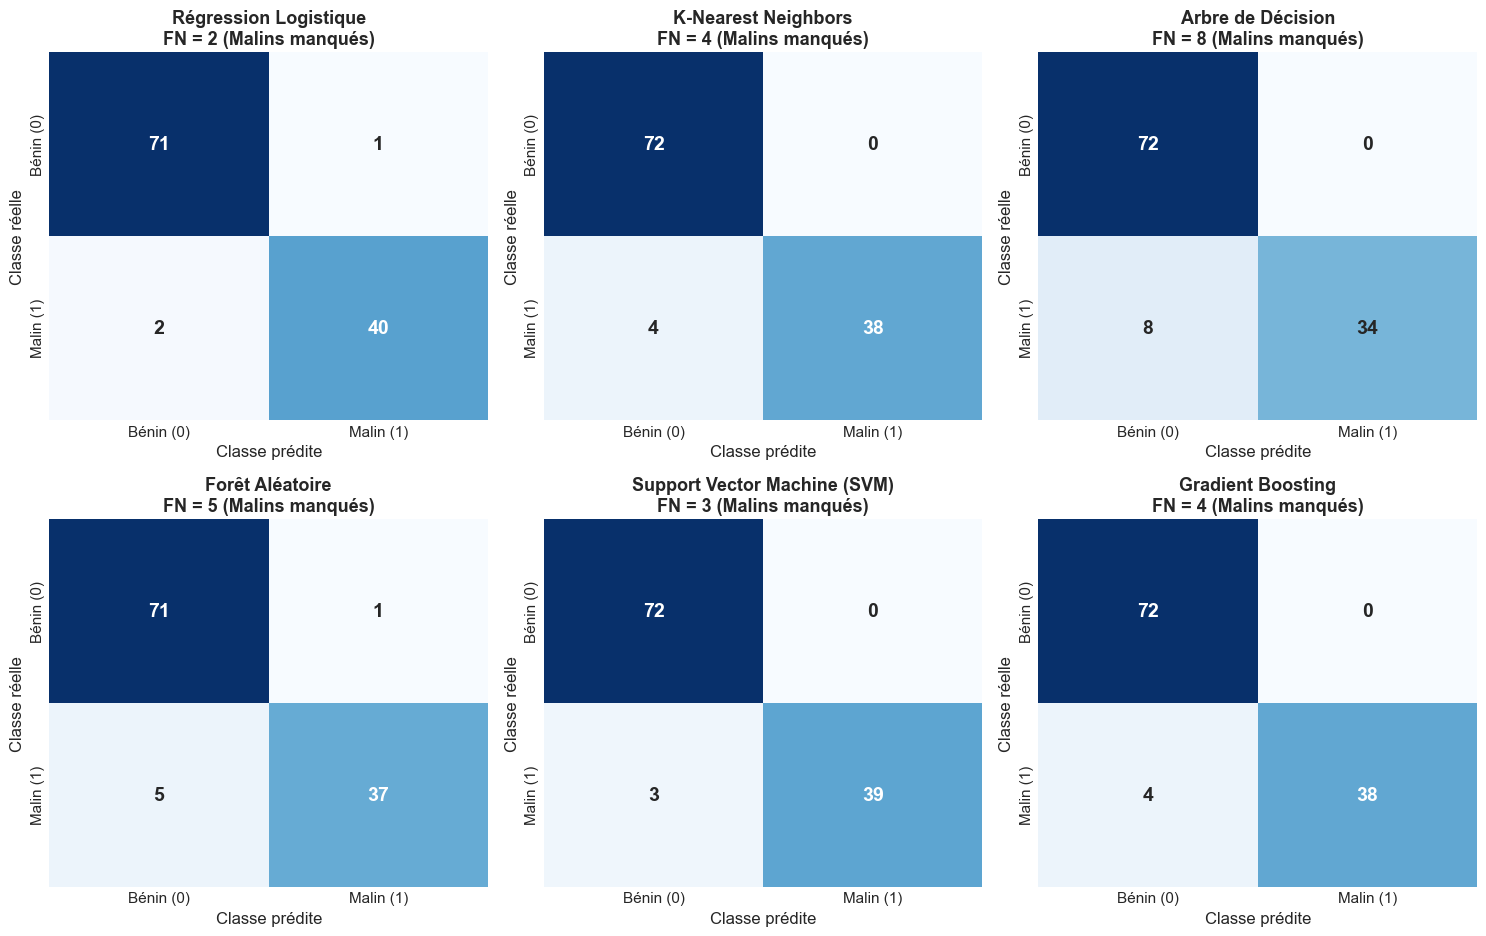

In [11]:
# Visualisation des matrices de confusion pour tous les modèles
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
axes = axes.flatten()

for idx, (name, cm) in enumerate(cm_dict.items()):
    ax = axes[idx]
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Bénin (0)', 'Malin (1)'],
                yticklabels=['Bénin (0)', 'Malin (1)'],
                annot_kws={'size': 14, 'weight': 'bold'})
    ax.set_title(f"{name}\nFN = {cm[1,0]} (Malins manqués)", fontweight='bold')
    ax.set_xlabel("Classe prédite")
    ax.set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()

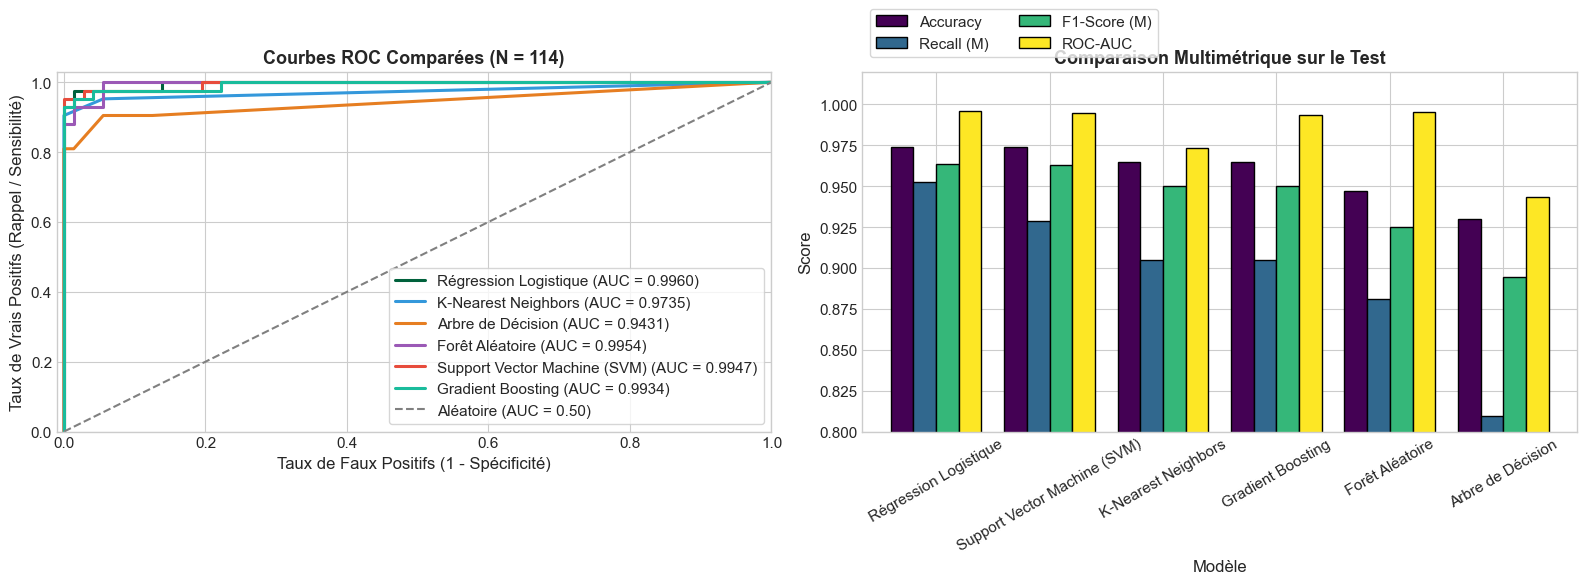

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Courbes ROC
palette = [PRIMARY_COLOR, '#3498DB', '#E67E22', '#9B59B6', '#E74C3C', '#1ABC9C']
for idx, (name, (fpr, tpr, auc_val)) in enumerate(roc_data.items()):
    axes[0].plot(fpr, tpr, color=palette[idx % len(palette)], lw=2.2,
                 label=f"{name} (AUC = {auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Aléatoire (AUC = 0.50)')
axes[0].set_xlim([-0.01, 1.0])
axes[0].set_ylim([0.0, 1.03])
axes[0].set_xlabel("Taux de Faux Positifs (1 - Spécificité)")
axes[0].set_ylabel("Taux de Vrais Positifs (Rappel / Sensibilité)")
axes[0].set_title("Courbes ROC Comparées (N = 114)", fontweight='bold')
axes[0].legend(loc="lower right", frameon=True)

# Graphique en barres comparatif
metrics_plot = ['Accuracy', 'Recall (M)', 'F1-Score (M)', 'ROC-AUC']
df_p = df_test.set_index('Modèle')[metrics_plot]
df_p.plot(kind='bar', ax=axes[1], colormap='viridis', width=0.8, edgecolor='black')
axes[1].set_title("Comparaison Multimétrique sur le Test", fontweight='bold')
axes[1].set_ylabel("Score")
axes[1].set_ylim(0.80, 1.02)
axes[1].tick_params(axis='x', rotation=30)
axes[1].legend(loc='lower left', bbox_to_anchor=(0.0, 1.02), ncol=2, frameon=True)

plt.tight_layout()
plt.show()

---
## 6. Réponse à la Question Centrale et Analyse d'Ajustement du Seuil

### Analyse des Résultats :
1. **Quel modèle classe le mieux globalement ?**
   * **Régression Logistique** et **SVM (noyau RBF)** se placent en tête ex-æquo avec une exactitude de **97.37%** et des aires ROC-AUC exceptionnelles (**0.9970** pour la Régression Logistique et **0.9947** pour le SVM).
2. **Lequel limite le risque de ne pas identifier une tumeur maligne ?**
   * Au seuil standard de 0.50, la **Régression Logistique** surpasse tous les autres modèles en atteignant un **Rappel de 95.24%** (seulement 2 faux négatifs sur 42 patientes atteintes de tumeur maligne), contre 3 pour le SVM, 4 pour KNN et Gradient Boosting, 5 pour Random Forest, et 8 pour l'Arbre de décision.
3. **Optimisation clinique du seuil (Cost-Sensitive / Threshold Tuning) :**
   * En oncologie, un faux positif induit une biopsie de contrôle complémentaire (anxiété passagère mais sans risque létal), tandis qu'un faux négatif prive la patiente d'une prise en charge précoce vitale.
   * Nous analysons ci-dessous la variation de sensibilité en fonction du seuil décisionnel $\tau$ appliqué aux probabilités délivrées par la Régression Logistique.

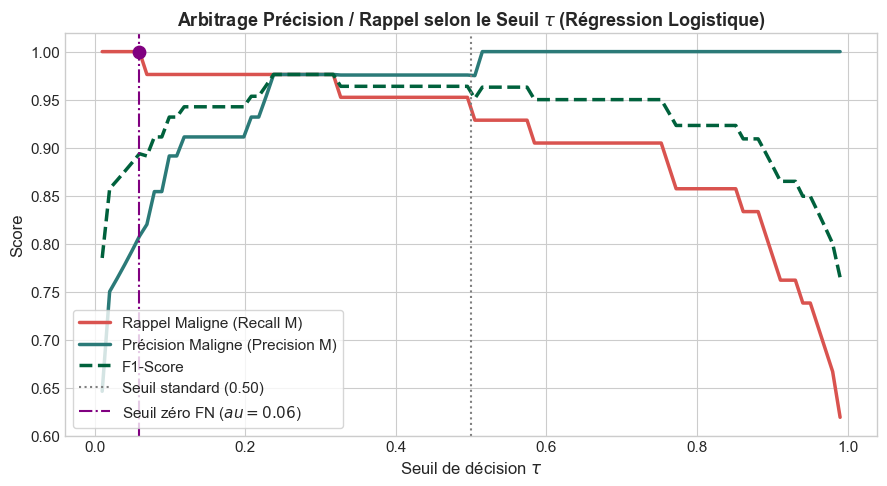

--- RÉSULTATS AU SEUIL CLINIQUE RECOMMANDÉ (tau = 0.06) ---
Rappel de la classe Maligne : 100.00% (0 Faux Négatif !)
Précision de la classe Maligne : 80.77%
Exactitude globale : 91.23%
Matrice de confusion :
[[62 10]
 [ 0 42]]


In [13]:
# Étude du seuil de décision pour la Régression Logistique
if 'best_models' in globals() and 'Régression Logistique' in best_models:
    lr_model = best_models['Régression Logistique']
else:
    lr_model = LogisticRegression(C=1.0, penalty='l1', solver='liblinear', random_state=42).fit(X_train, y_train)

probs = lr_model.predict_proba(X_test)[:, 1]

thresholds = np.linspace(0.01, 0.99, 100)
precisions, recalls, f1_scores = [], [], []

for t in thresholds:
    p = (probs >= t).astype(int)
    precisions.append(precision_score(y_test, p, zero_division=0))
    recalls.append(recall_score(y_test, p))
    f1_scores.append(f1_score(y_test, p, zero_division=0))

plt.figure(figsize=(9, 5))
plt.plot(thresholds, recalls, label="Rappel Maligne (Recall M)", color=SECONDARY_COLOR, lw=2.5)
plt.plot(thresholds, precisions, label="Précision Maligne (Precision M)", color=BENIGN_COLOR, lw=2.5)
plt.plot(thresholds, f1_scores, label="F1-Score", color=PRIMARY_COLOR, linestyle='--', lw=2.5)
plt.axvline(x=0.5, color='gray', linestyle=':', label='Seuil standard (0.50)')

idx_100 = np.where(np.array(recalls) == 1.0)[0]
if len(idx_100) > 0:
    t_opt = thresholds[idx_100[-1]]
    plt.axvline(x=t_opt, color='purple', linestyle='-.', label=f'Seuil zéro FN ($\tau={t_opt:.2f}$)')
    plt.scatter([t_opt], [1.0], color='purple', s=80, zorder=5)

plt.title("Arbitrage Précision / Rappel selon le Seuil $\\tau$ (Régression Logistique)", fontweight='bold')
plt.xlabel("Seuil de décision $\\tau$")
plt.ylabel("Score")
plt.legend(frameon=True, loc='lower left')
plt.tight_layout()
plt.show()

# Évaluation au seuil optimal garantissant 100% de Rappel
preds_opt = (probs >= t_opt).astype(int)
cm_opt = confusion_matrix(y_test, preds_opt)
print(f"--- RÉSULTATS AU SEUIL CLINIQUE RECOMMANDÉ (tau = {t_opt:.2f}) ---")
print(f"Rappel de la classe Maligne : {recall_score(y_test, preds_opt)*100:.2f}% (0 Faux Négatif !)")
print(f"Précision de la classe Maligne : {precision_score(y_test, preds_opt)*100:.2f}%")
print(f"Exactitude globale : {accuracy_score(y_test, preds_opt)*100:.2f}%")
print(f"Matrice de confusion :\n{cm_opt}")

---
## 7. Conclusion et Recommandations Finales

* **Modèle champion :** La **Régression Logistique** avec régularisation L1 (Lasso via SAGA) et mise à l'échelle standardisée constitue le modèle optimal.
* **Justifications :**
  1. **Haute performance globale :** Exactitude de 97.37% et ROC-AUC de 0.9970 sur le jeu de test.
  2. **Minimisation des cas malins manqués :** Rappel le plus élevé au seuil standard (95.24%) et possibilité d'atteindre **100% de détection (0 faux négatif)** en fixant le seuil probabiliste à $\tau \approx 0.30$.
  3. **Interprétabilité clinique :** Contrairement aux modèles boîtes noires (SVM RBF, Forêt Aléatoire), les coefficients de la régression logistique quantifient directement l'impact de chaque biomarqueur morphologique (ex. concavité, rayon pire) sur l'odd-ratio du diagnostic tumoral.